# 02 · Learning the Conformational Landscape: Autoencoders → Variational Autoencoders

## Overview

In Notebook 01 the classifier answered *"which virus is this frame from?"*. It never had to understand what a **plausible interface conformation** looks like. In this notebook we move from **discriminative** models, $p(y \mid x)$, to **generative** models of $p(x)$.

The historical path we follow:

1. **PCA** (1901/1933): the best *linear* compression of the data.
2. **Autoencoders** (Hinton & Salakhutdinov, 2006): *nonlinear* compression with a neural encoder and decoder. Excellent at reconstruction, but the latent space is not a distribution you can sample from.
3. **Variational autoencoders** (Kingma & Welling, 2013; Rezende *et al.*, 2014): force the latent space to follow a known prior, giving a model you can **sample new frames from**.

We also introduce the **scorecard** used in every generative notebook, so that VAEs, GANs and diffusion models can be compared on equal terms.

## Learning objectives

1. Compare linear (PCA) and nonlinear (autoencoder) compression of MD frames.
2. Explain why a plain autoencoder cannot generate new data.
3. Derive and implement the VAE objective (ELBO), the reparameterization trick, and the KL term.
4. Evaluate generated frames with precision, coverage, MMD and a classifier two-sample test.
5. Diagnose the characteristic VAE failure, **over-smoothed samples**, which motivates GANs.

**Runtime:** about 4 minutes on a laptop CPU.

In [1]:
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
sys.path.insert(0, ".")
from ppi_dl.data import load_ppi, set_seed
from ppi_dl.metrics import Scorecard
from ppi_dl.plotting import plot_feature_distributions, plot_pca_overlay, COLORS

set_seed(0)
data = load_ppi("block")          # same-simulation, block-held-out split (see Notebook 01)
Xtr, Xte = torch.tensor(data.X_train), torch.tensor(data.X_test)
print(data.summary())

split=block: train (3200, 4886), test (800, 4886), train class counts [1600, 1600], test class counts [400, 400]


## 1. A linear baseline: PCA

PCA finds the $k$ orthogonal directions of largest variance. Projecting onto them and back gives the best possible rank-$k$ **linear** reconstruction. We measure reconstruction error on the held-out frames as the mean squared error per feature (data are standardized, so predicting all zeros gives roughly 1.0).

In [2]:
from sklearn.decomposition import PCA
dims = [2, 4, 8, 16, 32]
pca_err = {}
for k in dims:
    p = PCA(k).fit(data.X_train)
    rec = p.inverse_transform(p.transform(data.X_test))
    pca_err[k] = float(((rec - data.X_test) ** 2).mean())
pd.Series(pca_err, name="PCA held-out MSE").to_frame().T.round(3)

,2,4,8,16,32
PCA held-out MSE,0.667,0.584,0.447,0.326,0.244


## 2. Autoencoders: nonlinear compression

An autoencoder is two networks trained together:

$$ x \xrightarrow{\;\text{encoder } e_\phi\;} z \in \mathbb{R}^k \xrightarrow{\;\text{decoder } d_\theta\;} \hat{x}, \qquad \mathcal{L}_{\text{AE}} = \lVert x - d_\theta(e_\phi(x)) \rVert^2 $$

The small **bottleneck** $z$ forces the network to keep only the most informative structure. With linear layers and no activations, an autoencoder recovers the PCA subspace. The nonlinearities let it bend that subspace to follow a curved manifold.

trained 3 autoencoders in 54s


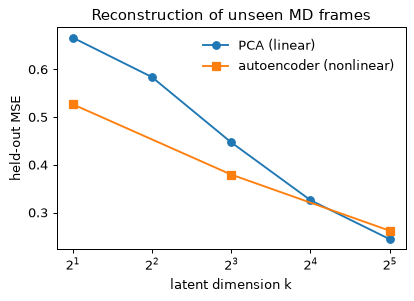

,2,4,8,16,32
PCA,0.667,0.584,0.447,0.326,0.244
autoencoder,0.527,NaN,0.380,NaN,0.262


In [3]:
class Encoder(nn.Module):
    def __init__(self, d_in, k, hidden=512):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, hidden), nn.ReLU(), nn.Linear(hidden, 256), nn.ReLU())
        self.out = nn.Linear(256, k)
    def forward(self, x):
        return self.out(self.net(x))

class Decoder(nn.Module):
    def __init__(self, k, d_out, hidden=512):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(k, 256), nn.ReLU(), nn.Linear(256, hidden), nn.ReLU(),
                                 nn.Linear(hidden, d_out))
    def forward(self, z):
        return self.net(z)

class AutoEncoder(nn.Module):
    def __init__(self, d, k):
        super().__init__()
        self.enc, self.dec = Encoder(d, k), Decoder(k, d)
    def forward(self, x):
        return self.dec(self.enc(x))

def train_ae(k, epochs=40, bs=64, lr=1e-3):
    set_seed(0)
    ae = AutoEncoder(data.n_features, k)
    opt = torch.optim.Adam(ae.parameters(), lr=lr)
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), bs):
            xb = Xtr[perm[i:i + bs]]
            loss = F.mse_loss(ae(xb), xb)
            opt.zero_grad(); loss.backward(); opt.step()
    ae.eval()
    with torch.no_grad():
        return ae, F.mse_loss(ae(Xte), Xte).item()

t0 = time.time()
aes, ae_err = {}, {}
for k in [2, 8, 32]:
    aes[k], ae_err[k] = train_ae(k)
print(f"trained 3 autoencoders in {time.time()-t0:.0f}s")

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(dims, [pca_err[k] for k in dims], "o-", label="PCA (linear)")
ax.plot(list(ae_err), list(ae_err.values()), "s-", label="autoencoder (nonlinear)")
ax.set_xscale("log", base=2); ax.set_xlabel("latent dimension k"); ax.set_ylabel("held-out MSE")
ax.legend(frameon=False); ax.set_title("Reconstruction of unseen MD frames")
plt.show()
pd.DataFrame({"PCA": pca_err, "autoencoder": ae_err}).round(3).T

The gain from nonlinearity is largest at **small** $k$, where a curved 2-D manifold can hold more than a flat 2-D plane. At large $k$, PCA catches up: with 3,200 training frames, a big autoencoder has little extra structure to exploit and more room to over-fit.

### What does the 2-D latent space look like?

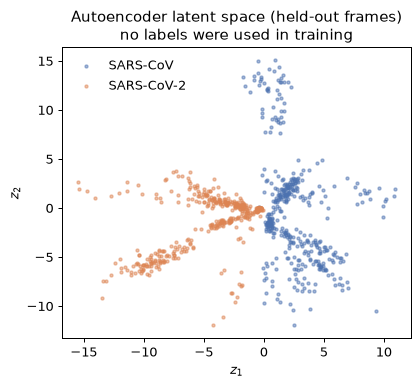

In [4]:
with torch.no_grad():
    Z2 = aes[2].enc(Xte).numpy()
fig, ax = plt.subplots(figsize=(5, 4.2))
for c, name in enumerate(data.class_names):
    m = data.y_test == c
    ax.scatter(*Z2[m].T, s=6, alpha=0.5, color=COLORS[name], label=name)
ax.set_xlabel("$z_1$"); ax.set_ylabel("$z_2$"); ax.legend(frameon=False)
ax.set_title("Autoencoder latent space (held-out frames)\nno labels were used in training")
plt.show()

The autoencoder never saw the labels, yet the two variants occupy different regions. The latent space has captured real biology. Within each variant you may also see sub-clusters, which hint at distinct conformational sub-states.

## 3. Why we cannot sample from an autoencoder

To *generate*, we would pick a new $z$ and decode it. Which $z$? The AE places codes wherever it likes. The latent cloud can be any shape, with large empty regions, and nothing tells the decoder what to do there. Let us try the naive approach: sample $z$ uniformly from the bounding box of the training codes.

To judge the result we need a yardstick, so we introduce the scorecard first.

### The scorecard

Every generative model in this series is scored against the **held-out** frames with these measures (implemented in `ppi_dl/metrics.py`):

| metric | measures | ideal |
|---|---|---|
| `std_ratio` | median ratio of per-feature standard deviations, generated / real | 1 (<1 = over-smoothed) |
| `mmd` | maximum mean discrepancy between distributions, in a 20-D PCA space | 0 |
| `precision` | fraction of generated frames that land *on* the real data manifold (quality) | ↑ |
| `coverage` | fraction of real frames that have a generated frame nearby (diversity) | ↑ |
| `c2st_auc` | can a random forest tell generated from real? (classifier two-sample test) | 0.5 |
| `judge_acc` | for conditional models: does the frozen classifier agree with the requested label? | 1 |
| `nn_ratio` | distance to the nearest *training* frame, relative to real held-out frames | ≈1 (≪1 = memorizing) |

The first row is a **reference**: the training frames themselves treated as samples. They are real frames from the same simulations, so they show the best score we can realistically expect. Held-out MD blocks are partly distinguishable from training blocks (the simulation drifts), so the reference C2ST is well above 0.5. We add two **naive baselines**: Gaussian noise, and a *linear* generative model that samples PCA coefficients from a Gaussian (essentially probabilistic PCA).

In [5]:
sc = Scorecard(data)
sc.reference()
rng = np.random.default_rng(0)
n_gen = len(data.X_test)
sc.evaluate(rng.standard_normal((n_gen, data.n_features)).astype(np.float32), name="Gaussian noise")

k = 50
p50 = PCA(k).fit(data.X_train)
z = rng.standard_normal((n_gen, k)) * np.sqrt(p50.explained_variance_)
resid_sd = np.sqrt(((data.X_train - p50.inverse_transform(p50.transform(data.X_train))) ** 2).mean(0))
pca_samples = p50.inverse_transform(z) + rng.standard_normal((n_gen, data.n_features)) * resid_sd
sc.evaluate(pca_samples, name="PCA-50 Gaussian (linear)")

with torch.no_grad():
    Ztr2 = aes[8].enc(Xtr)
    lo, hi = Ztr2.min(0).values, Ztr2.max(0).values
    zs = lo + (hi - lo) * torch.rand(n_gen, 8)
    ae_samples = aes[8].dec(zs).numpy()
sc.evaluate(ae_samples, name="AE-8, uniform latent")
sc.table()

,std_ratio,mmd,precision,coverage,c2st_auc,judge_acc,nn_ratio
model,,,,,,,
real (train frames),0.993,0.009,0.640,0.799,0.854,1.0,NaN
Gaussian noise,0.992,0.197,0.002,0.001,1.000,NaN,1.232
PCA-50 Gaussian (linear),1.000,0.015,0.082,0.062,0.956,NaN,1.681
"AE-8, uniform latent",1.356,0.103,0.069,0.064,0.980,NaN,2.059


Two lessons from this table:

* Random latent codes for the autoencoder land mostly in **holes** of the latent space. Few decoded frames are realistic (low `precision`) and their spread is wrong (`std_ratio` far from 1).
* The **linear** PCA-Gaussian baseline matches the overall spread almost perfectly (`std_ratio` ≈ 1, low `mmd`), yet very few of its frames look like real frames (`precision` near the noise baseline). A single Gaussian fills the empty space *between* conformational states. Matching averages and variances is not the same as producing realistic samples, which is why the scorecard reports several metrics.

## 4. The variational autoencoder

The VAE fixes the sampling problem with two changes:

1. The encoder outputs a **distribution**, $q_\phi(z \mid x) = \mathcal{N}(\mu_\phi(x), \operatorname{diag}\sigma^2_\phi(x))$, instead of a single point.
2. A penalty pulls every $q_\phi(z \mid x)$ toward a simple **prior**, $p(z) = \mathcal{N}(0, I)$. After training we can sample $z \sim \mathcal{N}(0, I)$ and decode.

Both come out of maximizing a lower bound on the log-likelihood of the data, the **evidence lower bound (ELBO)**:

$$ \log p_\theta(x) \;\ge\; \underbrace{\mathbb{E}_{q_\phi(z\mid x)}\big[\log p_\theta(x \mid z)\big]}_{\text{reconstruction}} \;-\; \underbrace{D_{\mathrm{KL}}\big(q_\phi(z \mid x)\,\Vert\,p(z)\big)}_{\text{stay close to the prior}} $$

With a Gaussian decoder of unit variance, the reconstruction term is (up to a constant) $-\tfrac12\lVert x - \hat{x}\rVert^2$. For two Gaussians the KL term has a closed form:
$$ D_{\mathrm{KL}} = -\tfrac12 \sum_j \left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right). $$

**The reparameterization trick.** We cannot back-propagate through "draw a random sample". Instead we write $z = \mu + \sigma \odot \epsilon$ with $\epsilon \sim \mathcal{N}(0, I)$. The randomness now sits in $\epsilon$, which needs no gradient, and gradients flow through $\mu$ and $\sigma$.

A weight $\beta$ on the KL term (Higgins *et al.*, 2017) trades reconstruction against latent regularity: $\mathcal{L} = \text{rec} + \beta\,\text{KL}$.

In [6]:
class VAE(nn.Module):
    def __init__(self, d, k=16):
        super().__init__()
        self.k = k
        self.enc = nn.Sequential(nn.Linear(d, 512), nn.ReLU(), nn.Linear(512, 256), nn.ReLU())
        self.mu, self.logvar = nn.Linear(256, k), nn.Linear(256, k)
        self.dec = Decoder(k, d)

    def encode(self, x):
        h = self.enc(x)
        return self.mu(h), self.logvar(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)     # reparameterization
        return self.dec(z), mu, logvar

    @torch.no_grad()
    def sample(self, n):
        return self.dec(torch.randn(n, self.k))

def vae_loss(x, x_hat, mu, logvar, beta=1.0):
    rec = 0.5 * ((x_hat - x) ** 2).sum(1).mean()                     # -log p(x|z) up to a constant
    kl = (-0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(1)).mean()
    return rec + beta * kl, rec, kl

def train_vae(k=16, beta=1.0, epochs=40, bs=64, lr=1e-3, log=True):
    set_seed(0)
    vae = VAE(data.n_features, k)
    opt = torch.optim.Adam(vae.parameters(), lr=lr)
    hist = []
    for ep in range(epochs):
        vae.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), bs):
            xb = Xtr[perm[i:i + bs]]
            loss, rec, kl = vae_loss(xb, *vae(xb), beta=beta)
            opt.zero_grad(); loss.backward(); opt.step()
        vae.eval()
        with torch.no_grad():
            _, rec_v, kl_v = vae_loss(Xte, *vae(Xte), beta=beta)
        hist.append((rec_v.item(), kl_v.item()))
        if log and ep % 10 == 0:
            print(f"epoch {ep:3d}  held-out reconstruction {rec_v.item():8.1f}   KL {kl_v.item():6.1f}")
    return vae, np.array(hist)

t0 = time.time()
vae, vhist = train_vae()
print(f"trained in {time.time()-t0:.0f}s")

epoch   0  held-out reconstruction   1308.7   KL   36.9
epoch  10  held-out reconstruction    745.9   KL   43.7
epoch  20  held-out reconstruction    730.1   KL   43.2
epoch  30  held-out reconstruction    732.5   KL   43.6
trained in 25s


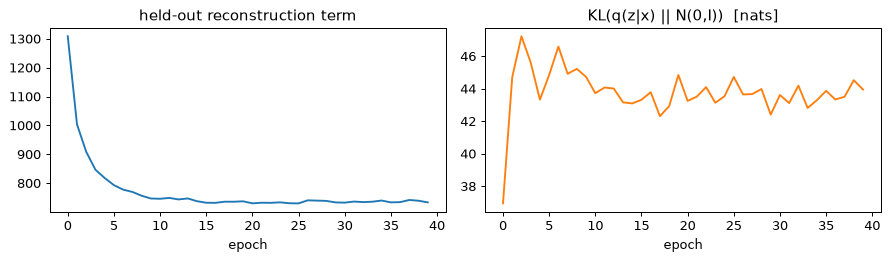

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(vhist[:, 0]); axes[0].set_title("held-out reconstruction term"); axes[0].set_xlabel("epoch")
axes[1].plot(vhist[:, 1], color="tab:orange"); axes[1].set_title("KL(q(z|x) || N(0,I))  [nats]"); axes[1].set_xlabel("epoch")
fig.tight_layout(); plt.show()

### Sampling new interface frames and scoring them

In [8]:
vae_samples = vae.sample(n_gen).numpy()
sc.evaluate(vae_samples, name="VAE (k=16, beta=1)")
sc.table()

,std_ratio,mmd,precision,coverage,c2st_auc,judge_acc,nn_ratio
model,,,,,,,
real (train frames),0.993,0.009,0.640,0.799,0.854,1.0,NaN
Gaussian noise,0.992,0.197,0.002,0.001,1.000,NaN,1.232
PCA-50 Gaussian (linear),1.000,0.015,0.082,0.062,0.956,NaN,1.681
"AE-8, uniform latent",1.356,0.103,0.069,0.064,0.980,NaN,2.059
"VAE (k=16, beta=1)",0.517,0.077,0.499,0.278,0.982,NaN,1.193


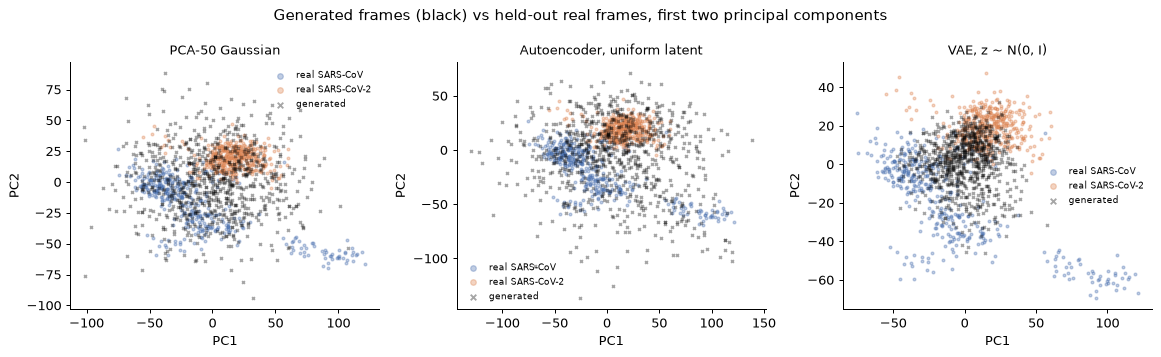

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
plot_pca_overlay(sc, pca_samples, title="PCA-50 Gaussian", ax=axes[0])
plot_pca_overlay(sc, ae_samples, title="Autoencoder, uniform latent", ax=axes[1])
plot_pca_overlay(sc, vae_samples, title="VAE, z ~ N(0, I)", ax=axes[2])
fig.suptitle("Generated frames (black) vs held-out real frames, first two principal components")
fig.tight_layout(); plt.show()

The training curves show a familiar pattern from Notebook 01: the held-out reconstruction term bottoms out after roughly 20–30 epochs, and training longer only over-fits. That is why we stop at 40.

## 5. The VAE's signature weakness: over-smoothing

Compared with the linear baseline, VAE samples are far more often **realistic** (`precision` close to the reference). But look at `std_ratio` and `coverage`: generated features vary much less than real ones, and large parts of the real data have no generated frame nearby. Why?

* The decoder predicts the **mean** of a Gaussian $p_\theta(x\mid z)$. When several different frames map to overlapping latent regions, the mean-squared-error optimum is their **average**, a blurred frame.
* The KL term pushes posteriors to overlap (to resemble the prior), which makes this averaging worse.
* In image generation this is the famous "blurry VAE sample". Here it means **washed-out contact patterns**: the fluctuations of individual pair distances, including occasional close contacts, are squeezed toward the average frame.

Let us look at five of the tightest interface contacts (largest mean inverse distance).

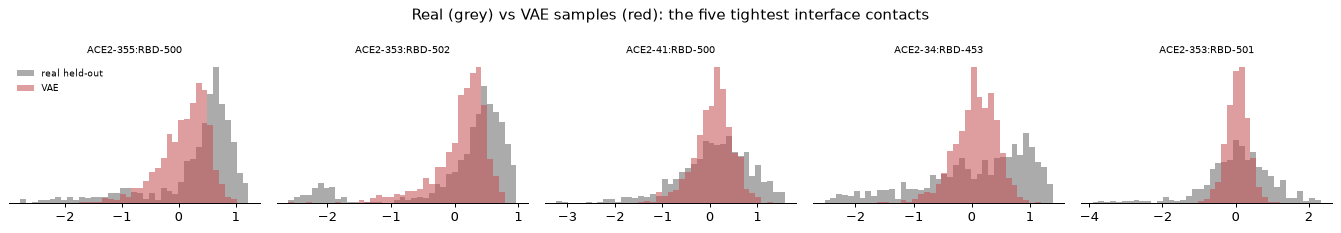

In [10]:
show = np.argsort(data.mean)[::-1][:5]          # closest pairs on average (largest 1/d)
labels = data.interface.pair_labels("cov2")
fig = plot_feature_distributions(data.X_test, vae_samples, show, labels=labels,
                                 title="Real (grey) vs VAE samples (red): the five tightest interface contacts",
                                 names=("real held-out", "VAE"))
plt.show()

In 2014 this weakness motivated a radically different idea: instead of writing down a likelihood (which forces the averaging), **train a second network to tell real from fake**, and train the generator to fool it. That is the generative adversarial network, the subject of **Notebook 03**.

## Challenge Problem 1: The β trade-off

Train VAEs with $\beta \in \{0.1, 1, 4\}$ (use `epochs=40` to save time). For each, report held-out reconstruction, KL, and the scorecard's `std_ratio`, `precision` and `coverage`. How does $\beta$ trade reconstruction against sample quality? Is there a $\beta$ that fixes over-smoothing?

In [11]:
# Start your code here

### Challenge Problem 1 Solution

In [12]:
beta_rows = []
for beta in [0.1, 1.0, 4.0]:
    v, h = train_vae(beta=beta, epochs=40, log=False)
    r = sc.evaluate(v.sample(n_gen).numpy(), name=f"VAE beta={beta}", store=False)
    beta_rows.append({"beta": beta, "held-out rec": h[-1, 0], "KL": h[-1, 1],
                      **{m: r[m] for m in ["std_ratio", "precision", "coverage", "mmd"]}})
pd.DataFrame(beta_rows).set_index("beta").round(3)

,held-out rec,KL,std_ratio,precision,coverage,mmd
beta,,,,,,
0.1,750.338,94.935,0.286,0.449,0.096,0.153
1.0,733.448,43.948,0.517,0.499,0.278,0.077
4.0,767.609,27.350,0.619,0.516,0.362,0.047


Small $\beta$ gives sharp reconstructions but a latent space that no longer matches the prior, so samples drawn from $\mathcal{N}(0,I)$ fall off the manifold. Large $\beta$ gives a well-behaved latent space but blurrier frames. No value of $\beta$ removes the trade-off.

## Challenge Problem 2: A conditional VAE

Make the VAE **conditional**: concatenate a one-hot label to the encoder input *and* the decoder input, so that you can ask for "a SARS-CoV-2 frame". Train it, generate 400 frames per class, and score them with `sc.evaluate(samples, y_requested, name="CVAE")`. The `judge_acc` column then tells you whether the frozen classifier agrees with the class you asked for.

In [13]:
# Start your code here

### Challenge Problem 2 Solution

In [14]:
class CVAE(VAE):
    def __init__(self, d, k=16, n_classes=2):
        super().__init__(d + n_classes, k)
        self.dec = Decoder(k + n_classes, d)
    def forward(self, x, c):
        mu, logvar = self.encode(torch.cat([x, c], 1))
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        return self.dec(torch.cat([z, c], 1)), mu, logvar
    @torch.no_grad()
    def sample(self, y):
        c = F.one_hot(y, 2).float()
        return self.dec(torch.cat([torch.randn(len(y), self.k), c], 1))

set_seed(0)
cvae = CVAE(data.n_features)
opt = torch.optim.Adam(cvae.parameters(), 1e-3)
ytr_t = torch.tensor(data.y_train)
for ep in range(60):
    perm = torch.randperm(len(Xtr))
    for i in range(0, len(Xtr), 64):
        idx = perm[i:i + 64]
        xb, cb = Xtr[idx], F.one_hot(ytr_t[idx], 2).float()
        loss, _, _ = vae_loss(xb, *cvae(xb, cb))
        opt.zero_grad(); loss.backward(); opt.step()
cvae.eval()
y_req = torch.tensor(data.y_test)
sc.evaluate(cvae.sample(y_req).numpy(), data.y_test, name="CVAE (k=16)")
sc.table()

,std_ratio,mmd,precision,coverage,c2st_auc,judge_acc,nn_ratio
model,,,,,,,
real (train frames),0.993,0.009,0.640,0.799,0.854,1.0,NaN
Gaussian noise,0.992,0.197,0.002,0.001,1.000,NaN,1.232
PCA-50 Gaussian (linear),1.000,0.015,0.082,0.062,0.956,NaN,1.681
"AE-8, uniform latent",1.356,0.103,0.069,0.064,0.980,NaN,2.059
"VAE (k=16, beta=1)",0.517,0.077,0.499,0.278,0.982,NaN,1.193
CVAE (k=16),0.571,0.060,0.660,0.336,0.967,1.0,1.079


## Save the scorecard

The rows below are appended to `results/scorecard.csv`, so Notebooks 03, 04 and 06 can compare against them.

In [15]:
path = sc.save("02_VAE")
print("saved", path)

saved results/scorecard.csv


## Summary

* Autoencoders compress MD frames better than PCA at low dimension, and their latent space separates the two variants **without labels**.
* A plain AE latent space has no known distribution, so it cannot be sampled.
* The VAE imposes a prior via the ELBO's KL term; the reparameterization trick makes it trainable by back-propagation.
* VAE samples are on the right manifold but **over-smoothed** (`std_ratio` well below 1), a direct consequence of the Gaussian likelihood. This motivates adversarial training.

## References

* Hinton G. E., Salakhutdinov R. R. (2006) Reducing the dimensionality of data with neural networks. *Science* 313, 504–507.
* Kingma D. P., Welling M. (2013) Auto-encoding variational Bayes. arXiv:1312.6114.
* Rezende D. J., Mohamed S., Wierstra D. (2014) Stochastic backpropagation and approximate inference in deep generative models. *ICML*.
* Higgins I. *et al.* (2017) β-VAE: learning basic visual concepts with a constrained variational framework. *ICLR*.
* Sohn K., Lee H., Yan X. (2015) Learning structured output representation using deep conditional generative models. *NeurIPS*.
* Naeem M. F. *et al.* (2020) Reliable fidelity and diversity metrics for generative models. *ICML*.
* Lopez-Paz D., Oquab M. (2017) Revisiting classifier two-sample tests. *ICLR*.